# Concentración crediticia: distribución finita y cola discreta
## Resumen
Dos carteras sintéticas con pérdida máxima300 y PD2% difieren en concentración. Resultados calculados abajo: oráculo de Bernoullis independientes vs normal con iguales momentos. Es exacto para el modelo sobre rejilla a precisión flotante, no evidencia de riesgo real.

## Contexto y método
Cada pérdida es $L=\sum_i w_i D_i$, $D_i\sim Bernoulli(p_i)$ independientes y $w_i$ entero no negativo. Polinomio generador: $G(z)=\prod_i[(1-p_i)+p_i z^{w_i}]$. La recurrencia $f_i(l)=(1-p_i)f_{i-1}(l)+p_i f_{i-1}(l-w_i)$ preserva masa. No aproximamos PD ni redondeamos exposiciones dentro del motor.

VaR es inversa izquierda de CDF; ES integra exactamente la masa superior1−q cortando el átomo frontera. No se usa E[L|L≥VaR] indiscriminadamente. El algoritmo ES respeta la convención ya existente en weighted-expected-shortfall-audit; lo nuevo es generar la distribución finita ponderada.

### Supuestos y pregunta falsable
PD conocidas, independencia, LGD/EAD deterministas incorporadas en pesos y horizonte único. ¿La normal infravalora ES99 concentrado más30%? ¿El PMF discreto coincide con enumeración fraccional con error≤1e−12? Son umbrales ex ante, no claims universales. La correlación sistémica es deliberadamente un caso negativo.

In [1]:
from pathlib import Path
import json,csv,math
from IPython.display import display,Image
from src.loss import independent_pmf,tail,normal_tail
root=Path.cwd()
metrics=json.loads((root/'results/metrics.json').read_text())
summary=list(csv.DictReader((root/'results/summary.csv').open()))
for row in summary: print(row)
print('Oráculo PMF error máximo:',metrics['max_oracle_pmf_error'])

{'case': 'granular', 'n': '100', 'total_loss': '300', 'hhi': '0.01', 'dp_var': '18.0', 'dp_es': '19.567309924665686', 'normal_var': '15.770661070971531', 'normal_es': '17.193899725452383', 'normal_es_relative_error': '-0.12129465973355323', 'mass_error': '2.3314683517128287e-15'}
{'case': 'concentrated', 'n': '21', 'total_loss': '300', 'hhi': '0.13333333333333333', 'dp_var': '100.0', 'dp_es': '108.000000000029', 'normal_var': '41.67740980205795', 'normal_es': '46.87434257387437', 'normal_es_relative_error': '-0.5659783095012798', 'mass_error': '4.440892098500626e-16'}
Oráculo PMF error máximo: 0.0


## Datos y resultados
Granular:100 posiciones de pérdida3; concentrada:una de100 y20 de10. Total300 y EL6 en ambas; HHI0,01 vs0,1333. La normal usa sus medias y varianzas propias exactas: comparación entre formas de distribución, no se oculta la varianza distinta. Los30 MonteCarlo usan10.000 draws/semilla y mismo DGP independiente por cartera. Boxplots son variación de estimadores, no confianza en riesgo bancario.

granular MC RMSE ES99 0.23607929811531117
concentrated MC RMSE ES99 1.199027383620367


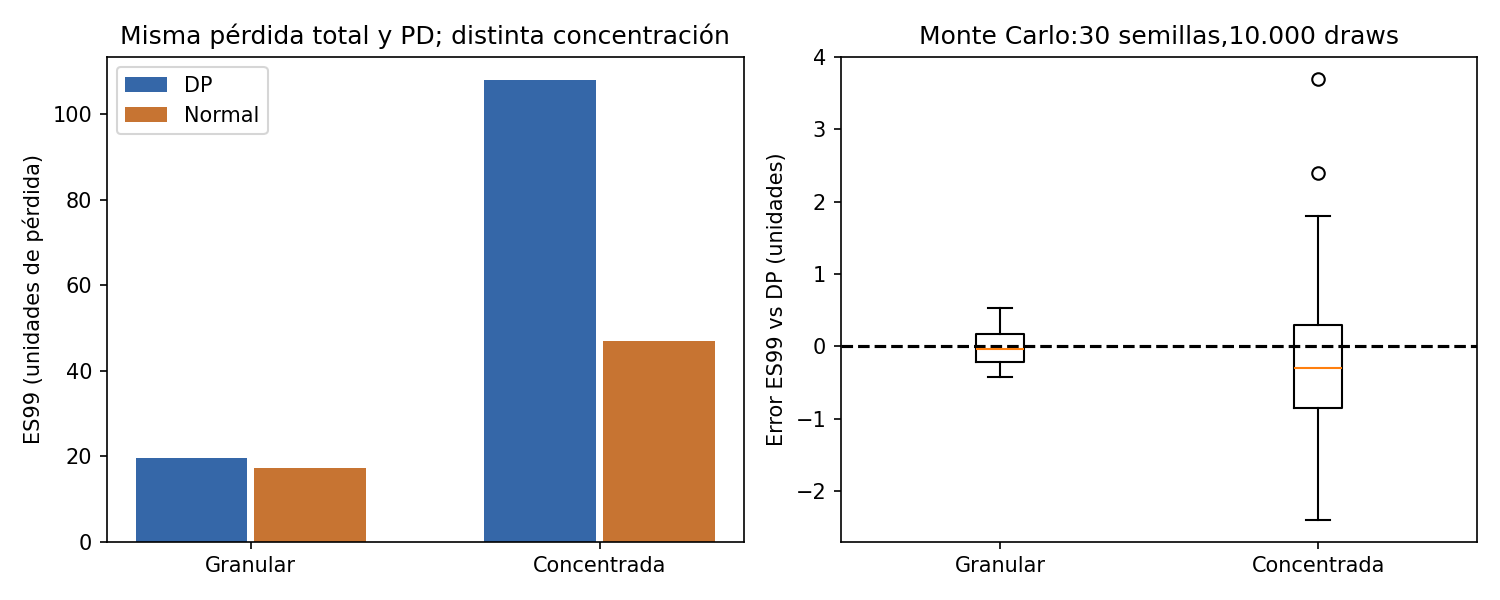

In [2]:
display(Image(filename=str(root/'results/audit.png')))
trials=list(csv.DictReader((root/'results/trials.csv').open()))
for name in ['granular','concentrated']:
 errors=[float(r['es_error']) for r in trials if r['case']==name]
 print(name,'MC RMSE ES99',math.sqrt(sum(e*e for e in errors)/len(errors)))

## Verificaciones y masa en el cuantil
Ejemplo PMF P(L0)=0,8 y P(L2)=0,2. ES50=0,8, mientras el promedio condicional L≥VaR50 mezcla toda la distribución y da0,4. La cola debe tener exactamente50% de masa, incluyendo0,3 en L0. No interpretar cola discreta como promedio de toda masa en la frontera.

In [3]:
assert abs(tail([.8,0,.2],.5).es-.8)<1e-12
assert metrics['hypothesis_concentration_passed']
assert metrics['oracle_tolerance_passed']
for weights in ([3]*100,[100]+[10]*20):
 pmf=independent_pmf(weights,[.02]*len(weights))
 assert abs(math.fsum(pmf)-1)<1e-12
 print('EL=',math.fsum(i*p for i,p in enumerate(pmf)),'tail=',tail(pmf,.99))
print('Checks passed')

EL= 5.999999999999985 tail= Tail(var=18.0, es=19.567309924665686)
EL= 5.999999999999998 tail= Tail(var=100.0, es=108.000000000029)
Checks passed


## Falsación: dependencia perfecta
Si todas las100 posiciones de3 incumplen juntas con probabilidad2%, la pérdida es0 o300: VaR99=ES99=300. El motor independiente granular predice18 y19,567. La exactitud numérica del modelo equivocado no protege contra dependencia omitida. No se implementa aquí Vasicek, IRB o un modelo regulatorio.

In [4]:
print('Shock común verdadero',metrics['negative_common_shock_var'],metrics['negative_common_shock_es'])
for row in csv.DictReader((root/'results/performance.csv').open()):print(row)
print('Tiempo/bytes pico proceso experimento',metrics['seconds'],metrics['peak_tracemalloc_bytes'])

Shock común verdadero 300.0 300.0
{'n': '20', 'lattice': '61', 'seconds': '0.0001426809999429679', 'mass_error': '4.440892098500626e-16'}
{'n': '100', 'lattice': '301', 'seconds': '0.001440881000007721', 'mass_error': '2.3314683517128287e-15'}
{'n': '300', 'lattice': '901', 'seconds': '0.013565698999968845', 'mass_error': '5.88418203051333e-15'}
Tiempo/bytes pico proceso experimento 0.24529249700003675 9916429


## Conclusiones y próximos pasos
La normal pierde asimetría y átomos; ni siquiera la cartera granular tiene muchos defaults esperados (solo2), así que no se presupone CLT preciso. El caso concentrado refuta uso automático de aproximación normal. Usar el DP como oráculo limitado para probar motores y cuantificar error numérico; no como certificación de capital. Añadir factor común, control de discretización y datos aprobados requeriría otra iteración. Cinco fuentes verificadas y detalles en informe.md/referencias.bib.